# Judging Books by Their Covers

In [29]:
import pandas as pd

df = pd.read_csv('data/books.csv', sep=';', encoding='latin1', escapechar='\\')
books_features = pd.read_csv('data/books_features.csv', low_memory=False)
ratings = pd.read_csv('data/ratings.csv', sep=';', encoding='latin1', escapechar='\\')
users = pd.read_csv('data/users.csv', sep=';', encoding='latin1', escapechar='\\')

sample = df.sample(300)
print(len(df))

# sample.to_csv('data/book_sample.csv', index=False, sep=';', encoding='latin1', escapechar='\\')

df.head()

271379


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


Extracted features. 96285 errors? All 1x1 pixel images?

In [30]:
books_features.head()



,isbn,error,color1_hex,color1_pct,color2_hex,color2_pct,color3_hex,color3_pct,text_color_hex,text_color_conf,contrast_rms,contrast_wcag_p5_p95,contrast_top2_deltaE,edge_density,mean_gradient,hf_energy_ratio,color_entropy,mean_lightness,mean_saturation,colorfulness
0,0002005018,NaN,#3d342d,0.2099,#d2694d,0.2067,#a35e4e,0.1830,#d99772,0.392,0.2099,10.363,57.45,0.2406,0.0573,0.3535,6.899,0.5102,0.4249,0.2685
1,0374157065,NaN,#efeead,0.3233,#f3f5d9,0.2920,#e2dc72,0.1636,#34424b,0.887,0.2254,9.954,18.95,0.3344,0.0832,0.1741,7.162,0.8187,0.2990,0.2273
2,0195153448,NaN,#baa68e,0.6376,#3f2b21,0.0974,#856a5b,0.0710,#140e0f,0.524,0.2160,8.339,49.88,0.2275,0.0474,0.1519,4.002,0.5540,0.2980,0.0972
3,0671870432,NaN,#15151a,0.4733,#30302b,0.1755,#b29d4f,0.1227,#dcddd4,0.908,0.2603,10.865,14.34,0.4561,0.1017,0.1752,5.661,0.2691,0.3542,0.1508
4,0425176428,NaN,#070404,0.6389,#3a3734,0.1052,#79716c,0.0807,#d8ccc4,0.986,0.2338,8.983,21.89,0.4051,0.0950,0.3698,3.744,0.1535,0.3252,0.1004


## Merge and clean datasets

In [31]:
# Rename 'isbn' to 'ISBN' in books_features to match the main dataframe
books_features = books_features.rename(columns={'isbn': 'ISBN'})

# Merge the books data with the extracted cover features
merged_df = pd.merge(df, books_features, on='ISBN', how='inner')

# Drop the 1x1 pixel image errors you identified
merged_df = merged_df[merged_df['error'].isna()]

# Ensure we only keep rows that successfully extracted all three colors
merged_df = merged_df.dropna(subset=['color1_hex', 'color2_hex', 'color3_hex'])

print(f"Total usable books: {len(merged_df)}")
merged_df[['ISBN', 'Book-Title', 'color1_hex', 'color2_hex', 'color3_hex']].head()

Total usable books: 174687


,ISBN,Book-Title,color1_hex,color2_hex,color3_hex
0,0195153448,Classical Mythology,#baa68e,#3f2b21,#856a5b
1,0002005018,Clara Callan,#3d342d,#d2694d,#a35e4e
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,#efeead,#f3f5d9,#e2dc72
4,0393045218,The Mummies of Urumchi,#fcfbfa,#b6a9a0,#99644b
6,0425176428,What If?: The World's Foremost Military Histor...,#070404,#3a3734,#79716c


## Convert colors to usable numbers for bayes

In [32]:
import colorsys

def hex_to_hsv(hex_color):
    """Converts a hex color string (e.g., '#baa68e') to H, S, V components."""
    if pd.isna(hex_color):
        return pd.Series([None, None, None])
    
    # Remove '#' and convert to RGB values between 0 and 1
    hex_color = str(hex_color).lstrip('#')
    r, g, b = tuple(int(hex_color[i:i+2], 16) / 255.0 for i in (0, 2, 4))
    
    # Convert to HSV
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    return pd.Series([h, s, v])

# Apply the conversion function to each of the three color columns
print("Converting Color 1...")
merged_df[['H1', 'S1', 'V1']] = merged_df['color1_hex'].apply(hex_to_hsv)

print("Converting Color 2...")
merged_df[['H2', 'S2', 'V2']] = merged_df['color2_hex'].apply(hex_to_hsv)

print("Converting Color 3...")
merged_df[['H3', 'S3', 'V3']] = merged_df['color3_hex'].apply(hex_to_hsv)

print("Conversion complete!")
merged_df[['ISBN', 'Book-Title', 'H1', 'S1', 'V1', 'H2', 'S2', 'V2']].head()

Converting Color 1...
Converting Color 2...
Converting Color 3...
Conversion complete!


,ISBN,Book-Title,H1,S1,V1,H2,S2,V2
0,0195153448,Classical Mythology,0.090909,0.236559,0.729412,0.055556,0.476190,0.247059
1,0002005018,Clara Callan,0.072917,0.262295,0.239216,0.035088,0.633333,0.823529
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,0.164141,0.276151,0.937255,0.178571,0.114286,0.960784
4,0393045218,The Mummies of Urumchi,0.083333,0.007937,0.988235,0.068182,0.120879,0.713725
6,0425176428,What If?: The World's Foremost Military Histor...,0.000000,0.428571,0.027451,0.083333,0.103448,0.227451


In [38]:
import requests
import pandas as pd
import time
from collections import defaultdict

# 1. Shuffle our entire merged dataset
df_shuffled = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 2. Setup tracking
target_per_genre = 30
genre_counts = defaultdict(int)
balanced_data = []

def clean_genre(genre_str):
    if not isinstance(genre_str, str): return None
    g = genre_str.lower()
    if 'fantasy' in g or 'magic' in g: return 'Fantasy'
    if 'science fiction' in g or 'sci-fi' in g: return 'Sci-Fi'
    if 'mystery' in g or 'thriller' in g or 'suspense' in g or 'detective' in g: return 'Mystery/Thriller'
    if 'romance' in g or 'love' in g: return 'Romance'
    if 'history' in g or 'historical' in g: return 'History'
    if 'biography' in g or 'memoir' in g: return 'Biography'
    if 'religion' in g or 'philosophy' in g: return 'Religion/Philosophy'
    if 'fiction' in g: return 'General Fiction'
    return 'Other'

print(f"Batch-hunting for books to fill quotas ({target_per_genre} per genre)...")

# 3. Process in batches of 50 to drastically reduce API calls
batch_size = 50
current_idx = 0

while current_idx < len(df_shuffled):
    # Stop condition: Check if we have successfully filled at least 4 genre buckets
    completed_genres = sum(1 for count in genre_counts.values() if count >= target_per_genre)
    if completed_genres >= 4:
        print("\nSuccessfully reached quotas for 4 different genres! Stopping search.")
        break
        
    if current_idx >= 3000: # Safety stop so it doesn't run forever
        print("\nReached max book search limit. Stopping.")
        break

    # Get the next batch of 50 books
    batch_df = df_shuffled.iloc[current_idx:current_idx + batch_size]
    current_idx += batch_size
    
    # Format the batch of ISBNs for the Open Library API (e.g., "ISBN:123,ISBN:456")
    isbns = batch_df['ISBN'].tolist()
    bibkeys = ",".join([f"ISBN:{isbn}" for isbn in isbns])
    
    url = f"https://openlibrary.org/api/books?bibkeys={bibkeys}&jscmd=data&format=json"
    
    try:
        response = requests.get(url, timeout=10)
        data = response.json()
        
        # Parse the batch results
        for index, row in batch_df.iterrows():
            key = f"ISBN:{row['ISBN']}"
            
            # If the API found the book and it has subjects
            if key in data and 'subjects' in data[key]:
                subjects = data[key]['subjects']
                if subjects:
                    raw_genre = subjects[0]['name']
                    clean_g = clean_genre(raw_genre)
                    
                    # Sort it into our balanced buckets
                    if clean_g and clean_g != 'Other':
                        if genre_counts[clean_g] < target_per_genre:
                            row_dict = row.to_dict()
                            row_dict['Raw_Genre'] = raw_genre
                            row_dict['Genre'] = clean_g
                            balanced_data.append(row_dict)
                            
                            genre_counts[clean_g] += 1
                            print(f"Found a {clean_g}! ({genre_counts[clean_g]}/{target_per_genre}) - {row['Book-Title']}")
                            
    except Exception as e:
        print("Batch failed or timed out, skipping to next batch...")
        
    # Brief pause to be polite to the Open Library servers
    time.sleep(1)

# 4. Convert our collected data back into the df_model dataframe
df_model = pd.DataFrame(balanced_data)

print(f"\nFinal usable books: {len(df_model)}")
if not df_model.empty:
    print("\nBalanced Genre Distribution for our Model:")
    print(df_model['Genre'].value_counts())

Batch-hunting for books to fill quotas (30 per genre)...
Found a General Fiction! (1/30) - Bet Your Life
Found a General Fiction! (2/30) - C.E.O. &amp; The Cookie Queen (Harlequin American Romance, 992)
Found a General Fiction! (3/30) - MUMBO JUMBO
Found a General Fiction! (4/30) - Sea of Swords (Forgotten Realms: Paths of Darkness)
Found a General Fiction! (5/30) - Distress
Found a General Fiction! (6/30) - The Oasis (Gedge, Pauline, Lords of the Two Lands, V. 2.)
Found a General Fiction! (7/30) - Dragons of a Lost Star (The War of Souls, Volume II)
Found a General Fiction! (8/30) - A Month At The Shore
Found a General Fiction! (9/30) - Moon Dancer
Found a General Fiction! (10/30) - Locked in the Library! : A Marc Brown Arthur Chapter Book 6 (Arthur Chapter Books)
Found a General Fiction! (11/30) - Absolute Zero
Found a Fantasy! (1/30) - I Who Never Known Men
Found a Mystery/Thriller! (1/30) - Loves Music, Loves to Dance
Found a Mystery/Thriller! (2/30) - Snobbery With Violence
Found 

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Define our features (X) and target label (y)
feature_cols = ['H1', 'S1', 'V1', 'H2', 'S2', 'V2', 'H3', 'S3', 'V3']
X = df_model[feature_cols]
y = df_model['Genre']

# 2. Split the dataset into training and testing sets (80% train, 20% test)
# random_state ensures we get the same split every time we run it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize the Gaussian Naive Bayes classifier
gnb = GaussianNB()

# 4. Train the model using our training data
gnb.fit(X_train, y_train)

# 5. Make predictions on the test set
y_pred = gnb.predict(X_test)

# 6. Evaluate and print the results
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
# zero_division=0 prevents warnings if a small class isn't predicted
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 0.16216216216216217

Classification Report:
                     precision    recall  f1-score   support

          Biography       0.00      0.00      0.00         6
            Fantasy       0.00      0.00      0.00         4
    General Fiction       0.20      0.25      0.22         4
            History       0.18      0.29      0.22         7
   Mystery/Thriller       0.17      0.14      0.15         7
Religion/Philosophy       0.00      0.00      0.00         2
            Romance       0.00      0.00      0.00         4
             Sci-Fi       0.29      0.67      0.40         3

           accuracy                           0.16        37
          macro avg       0.10      0.17      0.12        37
       weighted avg       0.11      0.16      0.13        37



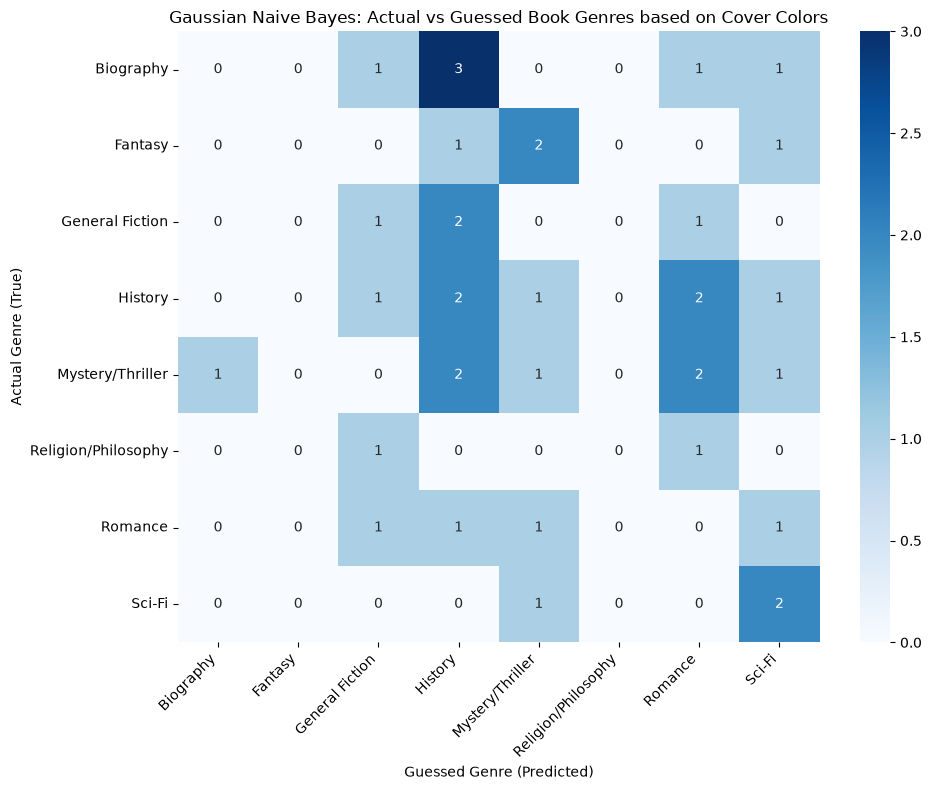

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=gnb.classes_)

# Create a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.xlabel('Guessed Genre (Predicted)')
plt.ylabel('Actual Genre (True)')
plt.title('Gaussian Naive Bayes: Actual vs Guessed Book Genres based on Cover Colors')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

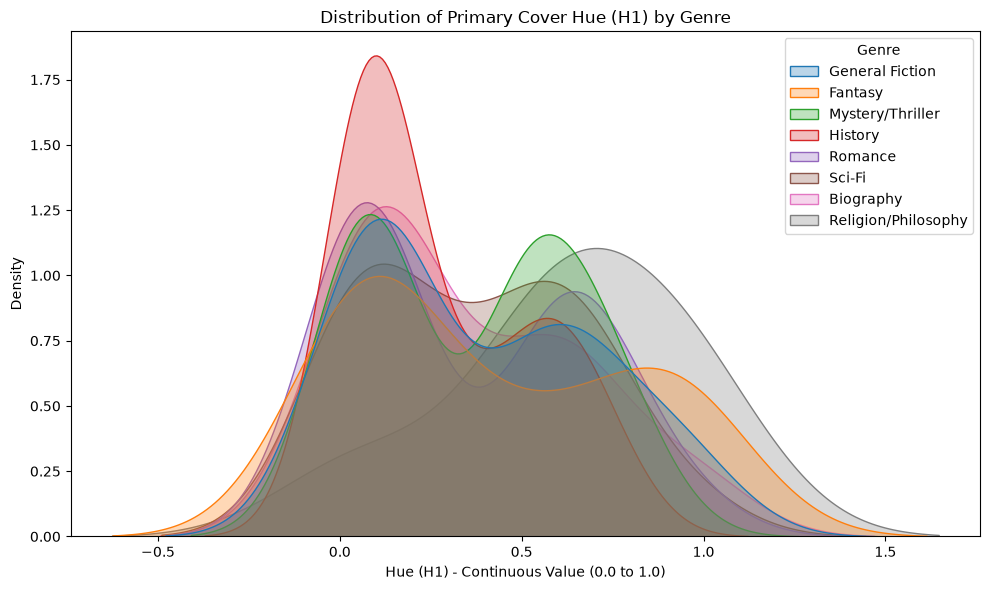

In [40]:
# Visualizing the distribution of the Primary Hue (H1) to show why Gaussian was chosen
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_model, x='H1', hue='Genre', common_norm=False, fill=True, alpha=0.3)
plt.title('Distribution of Primary Cover Hue (H1) by Genre')
plt.xlabel('Hue (H1) - Continuous Value (0.0 to 1.0)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()